# 02 Network structure and null models (Theme A: SQ1 + SQ2)

**SQ1.** Does network proximity (linked, few hops apart, heavy edge) go together with similar plots, beyond what
(i) the degree sequence and (ii) shared genre and release year explain?
**SQ2.** Which weighting of directors vs. actors makes the network correspond best to plot similarity?

Inputs
* `network/films_nodes.tsv`, `network/weightings/edges_<scheme>.tsv`: written by `build_network.py`
* `nlp/sim_tfidf.npy`, `nlp/sim_embed.npy`: Theme B. **Until B delivers, a provisional TF-IDF
  (raw plots, no NER removal) is used and the embedding analyses are skipped.** Rerun the notebook once
  the files exist; nothing else needs changing.

Outputs (in `results/network/`): `topology_table.csv/.tex`, `fig1_similarity_vs_distance.pdf`,
`fig2_sq2_correspondence.pdf`, `fig_ccdf.pdf`, the statistic tables, and the cached null ensembles (`nulls_<sim>.npz`).
The rewired networks for Theme C are written with `python network_tools.py rewire --n 100`
(network *i* = `rewire(seed=i)`, i.e. the first 100 of the 1000 used here).

Helper functions live in `network_tools.py` (documented there), so this notebook stays readable.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import network_tools as nt
from build_network import SCHEMES, SCHEME_DIRECTOR_WEIGHT

OUT = ROOT / "results" / "network"
OUT.mkdir(parents=True, exist_ok=True)
N_REWIRE = 1000      # degree-preserving networks
N_GENRE_YEAR = 1000  # genre/year-matched draws
N_PERM = 999         # Mantel / MRQAP permutations
pd.set_option("display.precision", 4)

# colours (validated categorical slots 1-3 + neutral grey for the rewiring null)
C_OBS, C_GY, C_REW, C_ALT = "#2a78d6", "#eb6834", "#8a8984", "#1baf7a"
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "font.size": 9, "lines.linewidth": 2})

## 0. Data

In [2]:
nodes = nt.load_nodes()
n = len(nodes)
W = {s: nt.weight_matrix(nt.load_edges(s), nodes) for s in SCHEMES}
W0 = W["dir2"]          # main network = films_edges.tsv (director weight 2)
A0 = W0 > 0

SIM = {}
for kind in ["tfidf", "embed"]:
    S = nt.load_similarity(kind, nodes)
    if S is not None:
        SIM[kind] = S
PROVISIONAL = not (ROOT / "nlp" / "sim_tfidf.npy").exists()
print(f"{n} films; similarity matrices: {list(SIM)}{'  (PROVISIONAL TF-IDF)' if PROVISIONAL else ''}")

# pair-level covariates (used by the regression)
G = nodes.genres.str.get_dummies(sep=",").to_numpy()
inter = G @ G.T
GENRE_JAC = inter / (G.sum(1)[:, None] + G.sum(1)[None, :] - inter)
YEAR_DIFF = np.abs(nodes.year.to_numpy()[:, None] - nodes.year.to_numpy()[None, :]).astype(float)

/Users/emretaspinar/Desktop/Social Graphs/SocialGraphs/network_tools.py:102: UserWarning: /Users/emretaspinar/Desktop/Social Graphs/SocialGraphs/nlp/sim_tfidf.npy not found: using provisional TF-IDF (raw plots, no NER removal)
  warnings.warn(f"{path} not found: using provisional TF-IDF (raw plots, no NER removal)")


1789 films; similarity matrices: ['tfidf']  (PROVISIONAL TF-IDF)


/Users/emretaspinar/Desktop/Social Graphs/SocialGraphs/network_tools.py:104: UserWarning: /Users/emretaspinar/Desktop/Social Graphs/SocialGraphs/nlp/sim_embed.npy not found: skipping 'embed'
  warnings.warn(f"{path} not found: skipping '{kind}'")


## 1. Weighting schemes and topology (SQ2)

Seven schemes, all from the same people data (`build_network.py`, `SCHEMES`). `dir1`–`dir10` and `billing`
share the same edge set and differ only in weights; `actors` and `directors` drop the other kind of tie.
Shortest paths use distance = 1/weight. Weighted clustering is the Onnela et al. geometric-mean version
(networkx, weights scaled by the maximum weight).

In [3]:
topo = pd.DataFrame({s: nt.topology_summary(W[s]) for s in SCHEMES}).T
topo.index.name = "scheme"
topo.to_csv(OUT / "topology_table.csv")
fmt = {c: "{:.0f}" if topo[c].max() > 50 or c in ("isolates", "max degree") else "{:.3f}" for c in topo}
topo.T.to_latex(OUT / "topology_table.tex", float_format="%.3g")
topo.style.format(fmt)

,nodes,edges,density,mean degree,max degree,mean strength,isolates,components (size>1),giant component %,clustering (unweighted),clustering (weighted),transitivity,degree assortativity,"avg shortest path (hops, GCC)","avg shortest path (1/w, GCC)","diameter (hops, GCC)"
scheme,,,,,,,,,,,,,,,,
actors,1789,10815,0.007,12.091,40,12.178,144,8,91,0.455,0.154,0.443,0.389,3.710,3.697,11.000
directors,1789,1173,0.001,1.311,8,1.362,704,395,1,0.351,0.121,0.995,0.995,1.000,1.000,1.000
dir1,1789,11802,0.007,13.194,42,13.539,83,9,94,0.410,0.086,0.397,0.388,3.593,3.505,10.000
dir2,1789,11802,0.007,13.194,42,14.901,83,9,94,0.410,0.067,0.397,0.388,3.593,3.146,10.000
dir4,1789,11802,0.007,13.194,42,17.624,83,9,94,0.410,0.046,0.397,0.388,3.593,2.896,10.000
dir10,1789,11802,0.007,13.194,42,25.794,83,9,94,0.410,0.026,0.397,0.388,3.593,2.730,10.000
billing,1789,11802,0.007,13.194,42,11.087,83,9,94,0.410,0.059,0.397,0.388,3.593,4.465,10.000


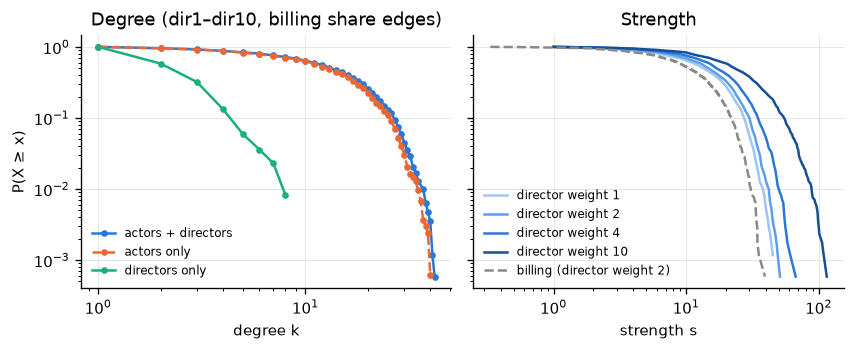

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 3), sharey=True)
for s, col, ls, lab in [("dir2", C_OBS, "-", "actors + directors"),
                        ("actors", C_GY, "--", "actors only"), ("directors", C_ALT, "-", "directors only")]:
    x, y = nt.ccdf((W[s] > 0).sum(1))
    axes[0].loglog(x, y, ls, marker="o", ms=3, lw=1.5, color=col, label=lab)
blues = ["#9ec5f4", "#5c9fe8", "#2a78d6", "#174f96"]
for s, col in zip(["dir1", "dir2", "dir4", "dir10"], blues):
    x, y = nt.ccdf(W[s].sum(1))
    axes[1].loglog(x, y, "-", lw=1.5, color=col, label=f"director weight {s[3:]}")
x, y = nt.ccdf(W["billing"].sum(1))
axes[1].loglog(x, y, "--", lw=1.5, color=C_REW, label="billing (director weight 2)")
axes[0].set(xlabel="degree k", ylabel="P(X ≥ x)", title="Degree (dir1–dir10, billing share edges)")
axes[1].set(xlabel="strength s", title="Strength")
for ax in axes: ax.legend(frameon=False, fontsize=7)
fig.tight_layout(); fig.savefig(OUT / "fig_ccdf.pdf"); plt.show()

Most central films in the main network (betweenness on distance = 1/weight; eigenvector centrality on the giant component).

In [5]:
cent = nt.top_centrality(W0, nodes, n=10)
cent.to_csv(OUT / "top_centrality_dir2.csv")
cent

,betweenness,eigenvector
rank,,
1,You Will Meet a Tall Dark Stranger (0.009),The Fighter (0.156)
2,Midnight in Paris (0.008),Joy (0.142)
3,Café Society (0.008),Silver Linings Playbook (0.142)
4,Pain & Gain (0.008),American Hustle (0.134)
5,The Martian (0.007),Date Night (0.127)
6,Joe (0.007),Vice (0.125)
7,This Means War (0.007),The Big Short (0.124)
8,In a Valley of Violence (0.007),The Other Guys (0.111)
9,Being Flynn (0.006),Daddy's Home 2 (0.109)


## 2. Structure vs. plot similarity (SQ1)

For each similarity matrix *S*:
* linked vs. unlinked pairs: means, Cohen's *d*, AUC = P(similarity of a random linked pair > a random unlinked pair);
* Spearman ρ of edge weight vs. similarity over the edges;
* mean similarity by hop distance (1, 2, 3, 4+, disconnected);
* Mantel tests (Spearman, 999 node permutations) of *S* against the weight matrix and against network
  proximity = −hops (disconnected pairs get the largest hop distance + 1).
  Film pairs share films, so ordinary p-values would be far too small; the Mantel test permutes films instead.

In [6]:
iu = np.triu_indices(n, 1)
H0 = nt.hop_matrix(W0)
hop_c = nt.hop_classes(H0[iu])
linked = A0[iu]
PROX = -np.where(np.isfinite(H0), H0, np.nanmax(H0[np.isfinite(H0)]) + 1)

obs, rows = {}, []
for kind, S in SIM.items():
    s = S[iu]
    ew = W0[iu][linked]
    rho, _ = stats.spearmanr(ew, s[linked])
    o = {**nt.linked_vs_unlinked(s, linked), "spearman weight~sim (edges)": rho,
         "by_hop": nt.sim_by_hop(s, hop_c)}
    o["mantel W"] = nt.mantel(S, W0, N_PERM)
    o["mantel prox"] = nt.mantel(S, PROX, N_PERM)
    obs[kind] = o
    rows.append({"similarity": kind, **{k: v for k, v in o.items() if not isinstance(v, (dict, np.ndarray))},
                 "Mantel r (weight)": o["mantel W"]["r"], "p": o["mantel W"]["p"],
                 "Mantel r (proximity)": o["mantel prox"]["r"], "p ": o["mantel prox"]["p"]})
sq1 = pd.DataFrame(rows).set_index("similarity")
sq1.to_csv(OUT / "sq1_observed.csv")
display(sq1.T)
pd.DataFrame({k: v["by_hop"] for k, v in obs.items()}, index=pd.Index(nt.HOP_LABELS, name="hops")) \
  .assign(pairs=np.bincount(hop_c, minlength=5))

similarity,tfidf
mean linked,0.0343
mean unlinked,0.0310
ratio,1.1073
cohen d,0.2186
AUC (P[linked > unlinked]),0.5503
spearman weight~sim (edges),0.0872
Mantel r (weight),0.0149
p,0.0010
Mantel r (proximity),0.0103
p,0.1790


,tfidf,pairs
hops,,
1,0.0343,11802
2,0.0317,113852
3,0.0310,554871
4+,0.0309,743315
disc.,0.0308,175526


## 3. Null models

**(i) Degree-preserving rewiring.** 1000 networks, each from 10·|E| double-edge swap attempts
(`nt.rewire`, seed = network index). Edges carry their weights, so degrees and the weight distribution are
kept exactly. This asks: is the similarity of linked / nearby films more than expected from *which films are
well connected*? (Popular, prolific-star films could simply have more generic plots.)

**(ii) Genre- and year-matched random pairs.** Every film pair (*i*, *j*) is replaced by (*i*, *j'*), where *j'*
is a random film with the same IMDb genre set and release year ±1 as *j* (fallbacks in `nt.genre_year_pools`),
not *i* and not linked to *i*. The matched pairs have the same genre composition and year gap as the real ones
but no collaboration, so the band shows how much of the similarity at each hop distance genre and era alone
explain (typecasting: actors and directors stay within genres).

For each statistic we report z = (observed − null mean) / null sd and an empirical two-sided p.
Both ensembles are cached in `results/network/nulls_<sim>.npz`; delete the file to recompute.

In [7]:
ei, ej = np.nonzero(np.triu(A0, 1))
ew_all = W0[ei, ej]
pools = nt.genre_year_pools(nodes)
print("genre/year pool tiers (same set & ±1y, same set, ≥2 shared & ±1y, ≥1 shared):",
      np.bincount(pools[3], minlength=4), "| median pool size", int(np.median(pools[2])))

def rewired_stats(S_list, seed):
    a, b, src, _ = nt.rewire(ei, ej, n, seed)
    Wr = np.zeros((n, n)); Wr[a, b] = Wr[b, a] = ew_all[src]
    c = nt.hop_classes(nt.hop_matrix(Wr)[iu])
    lk, wr = Wr[iu] > 0, Wr[iu]
    out = []
    for S in S_list:
        s = S[iu]
        out.append(np.r_[nt.sim_by_hop(s, c), s[lk].mean(),
                         (s[lk].mean() - s[~lk].mean()) / s.std(),
                         stats.spearmanr(wr[lk], s[lk])[0], nt._corr(stats.rankdata(s), stats.rankdata(wr))])
    return out

STAT_NAMES = [f"sim @ {h} hops" for h in nt.HOP_LABELS] + ["mean sim linked", "std. diff linked-unlinked",
                                                          "spearman weight~sim (edges)", "Mantel r (weight)"]
def observed_vector(S):
    s = S[iu]
    return np.r_[nt.sim_by_hop(s, hop_c), s[linked].mean(), (s[linked].mean() - s[~linked].mean()) / s.std(),
                 stats.spearmanr(W0[iu][linked], s[linked])[0], nt._corr(stats.rankdata(s), stats.rankdata(W0[iu]))]

genre/year pool tiers (same set & ±1y, same set, ≥2 shared & ±1y, ≥1 shared): [1241  353  185   10] | median pool size 10


In [8]:
kinds = list(SIM)
tag = "provisional" if PROVISIONAL else "final"
cache = OUT / f"nulls_{'_'.join(kinds)}_{tag}_v2.npz"  # bump the version when the statistics change
if cache.exists():
    z = np.load(cache)
    REW = {k: z[f"rew_{k}"] for k in kinds}; GY = {k: z[f"gy_{k}"] for k in kinds}
else:
    res = [rewired_stats([SIM[k] for k in kinds], seed) for seed in range(N_REWIRE)]
    REW = {k: np.array([r[m] for r in res]) for m, k in enumerate(kinds)}
    rng = np.random.default_rng(12345)
    pi, pj = iu
    GY = {k: [] for k in kinds}
    for _ in range(N_GENRE_YEAR):
        # same random j' for both similarity measures, so they are comparable
        state = rng.bit_generator.state
        for k in kinds:
            rng.bit_generator.state = state
            sm = nt.genre_year_null(SIM[k], A0, pi, pj, pools, rng)
            ok = ~np.isnan(sm)
            GY[k].append(np.r_[nt.sim_by_hop(sm[ok], hop_c[ok]), np.nanmean(sm[linked])])
    GY = {k: np.array(v) for k, v in GY.items()}
    np.savez(cache, **{f"rew_{k}": REW[k] for k in kinds}, **{f"gy_{k}": GY[k] for k in kinds})
print({k: (REW[k].shape, GY[k].shape) for k in kinds})

{'tfidf': ((1000, 9), (1000, 6))}


In [9]:
def emp_p(o, null):
    null = null[~np.isnan(null)]
    return (1 + min((null >= o).sum(), (null <= o).sum()) * 2) / (len(null) + 1)

ztab = []
for k in kinds:
    o = observed_vector(SIM[k])
    for m, name in enumerate(STAT_NAMES):
        row = {"similarity": k, "statistic": name, "observed": o[m],
               "rewired mean": REW[k][:, m].mean(), "z (rewired)": nt.zscore(o[m], REW[k][:, m]),
               "p (rewired)": min(1, emp_p(o[m], REW[k][:, m]))}
        if m < 6:  # genre/year null exists for the hop classes and the linked mean
            row.update({"genre/year mean": np.nanmean(GY[k][:, m]),
                        "z (genre/year)": nt.zscore(o[m], GY[k][:, m]),
                        "p (genre/year)": min(1, emp_p(o[m], GY[k][:, m]))})
        ztab.append(row)
ztab = pd.DataFrame(ztab).set_index(["similarity", "statistic"])
ztab.to_csv(OUT / "sq1_null_zscores.csv")
ztab

observed  rewired mean  z (rewired)  \
similarity statistic                                                          
tfidf      sim @ 1 hops                   0.0343        0.0312      26.9941   
           sim @ 2 hops                   0.0317        0.0311      13.4246   
           sim @ 3 hops                   0.0310        0.0310       0.4931   
           sim @ 4+ hops                  0.0309        0.0309      -0.5130   
           sim @ disc. hops               0.0308        0.0310      -7.0407   
           mean sim linked                0.0343        0.0312      26.9941   
           std. diff linked-unlinked      0.2186        0.0096      26.9941   
           spearman weight~sim (edges)    0.0872       -0.0002       9.3495   
           Mantel r (weight)              0.0149        0.0007      22.1417   

                                        p (rewired)  genre/year mean  \
similarity statistic                                                   
tfidf      sim @ 1 hops                      0.0010           0.0325   
           sim @ 2 hops                      0.0010           0.0314   
           sim @ 3 hops                      0.5964           0.0310   
           sim @ 4+ hops                     0.6024           0.0310   
           sim @ disc. hops                  0.0030           0.0310   
           mean sim linked                   0.0010           0.0325   
           std. diff linked-unlinked         0.0010              NaN   
           spearman weight~sim (edges)       0.0010              NaN   
           Mantel r (weight)                 0.0010              NaN   

                                        z (genre/year)  p (genre/year)  
similarity statistic                                                    
tfidf      sim @ 1 hops                        15.6602          0.0010  
           sim @ 2 hops                         8.1192          0.0010  
           sim @ 3 hops                         1.4801          0.1489  
           sim @ 4+ hops                       -5.7087          0.0010  
           sim @ disc. hops                    -9.5497          0.0010  
           mean sim linked                     15.6602          0.0010  
           std. diff linked-unlinked               NaN             NaN  
           spearman weight~sim (edges)             NaN             NaN  
           Mantel r (weight)                       NaN             NaN

### Figure 1: plot similarity vs. network distance, with null-model bands

Points: observed mean similarity of film pairs at each hop distance in the main network (director weight 2).
Grey band: 95% range over 1000 degree-preserving rewired networks. Orange band: 95% range over 1000
genre- and year-matched random pairings. Similarity is shown relative to the mean over all pairs.

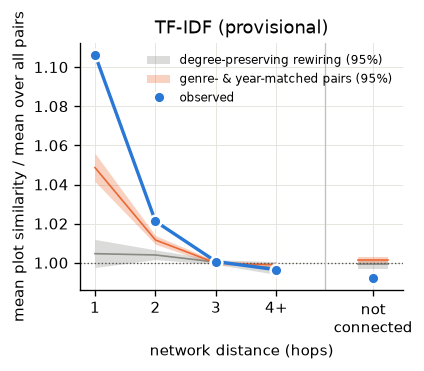

In [10]:
x = np.array([0, 1, 2, 3, 4.6])   # gap before "not connected": it is not a distance step
fig, axes = plt.subplots(1, len(kinds), figsize=(3.6 * len(kinds), 3.1), squeeze=False)
for ax, k in zip(axes[0], kinds):
    base = SIM[k][iu].mean()
    for null, col, lab in [(REW[k][:, :5], C_REW, "degree-preserving rewiring"),
                           (GY[k][:, :5], C_GY, "genre- & year-matched pairs")]:
        lo, hi = np.nanpercentile(null, [2.5, 97.5], axis=0) / base
        mid = np.nanmean(null, 0) / base
        ax.fill_between(x[:4], lo[:4], hi[:4], color=col, alpha=0.3, lw=0, label=f"{lab} (95%)")
        ax.plot(x[:4], mid[:4], color=col, lw=1)
        xx = x[4] + np.array([-0.25, 0.25])
        ax.fill_between(xx, [lo[4]] * 2, [hi[4]] * 2, color=col, alpha=0.3, lw=0)
        ax.plot(xx, [mid[4]] * 2, color=col, lw=1)
    y = obs[k]["by_hop"] / base
    ax.plot(x[:4], y[:4], "-", color=C_OBS, zorder=5)
    ax.plot(x, y, "o", color=C_OBS, ms=7, label="observed", markeredgecolor="white",
            markeredgewidth=1.5, zorder=6)
    ax.axhline(1, color="#52514e", lw=0.8, ls=":")
    ax.axvline(3.8, color="#c3c2b7", lw=0.8)
    ax.set_xticks(x, ["1", "2", "3", "4+", "not\nconnected"])
    title = {"tfidf": "TF-IDF", "embed": "Sentence embeddings"}[k] + (" (provisional)" if k == "tfidf" and PROVISIONAL else "")
    ax.set(xlabel="network distance (hops)", ylabel="mean plot similarity / mean over all pairs", title=title)
axes[0][0].legend(frameon=False, fontsize=7, loc="upper right")
fig.tight_layout(); fig.savefig(OUT / "fig1_similarity_vs_distance.pdf"); plt.show()

## 4. Controlled regression (MRQAP)

similarity ~ linked + weight + genre overlap (Jaccard of IMDb genre sets) + |year difference|, over all
1.6 M film pairs. Predictors are standardised (β = change in similarity per SD). p-values from MRQAP with
double-semi-partialling (Dekker et al. 2007, 999 permutations): each predictor is residualised on the others
and its residual matrix is permuted by film, which is robust to the collinearity between *linked* and *weight*.

In [11]:
reg = {}
for k in kinds:
    tab, r2 = nt.mrqap(SIM[k], {"linked": A0.astype(float), "weight": W0, "genre overlap": GENRE_JAC,
                                "|year difference|": YEAR_DIFF}, n_perm=N_PERM)
    tab["R²"] = r2
    reg[k] = tab
reg = pd.concat(reg, names=["similarity", "predictor"])
reg.to_csv(OUT / "mrqap.csv")
reg

beta (per SD)         t  p (MRQAP)      R²
similarity predictor                                                    
tfidf      linked               -6.6467e-04  -19.9801      0.001  0.0459
           weight                9.0865e-04   27.3112      0.001  0.0459
           genre overlap         3.2266e-03  274.4738      0.001  0.0459
           |year difference|    -2.8230e-05   -2.4028      0.754  0.0459

## 5. Which weighting fits best? (SQ2)

**Pre-chosen correspondence metric: Pearson Mantel r between plot similarity and the weight matrix**
(unlinked pairs = 0), one value per scheme; p-values from 999 film permutations.

Why Pearson and not Spearman: `dir1`–`dir10` and `billing` share one edge set, and the 1.6 M unlinked pairs all tie
at 0, so a rank correlation barely moves when edges are reweighted (Spearman Mantel r = 0.0149 for all five), and
director weights 2, 4 and 10 even give the same edge *ranking*. Pearson responds to how much heavier the
director ties are, which is exactly what SQ2 asks.

Differences between schemes are small, so significance against zero is not enough. We draw 200 random subsets
of 80% of the films and compute every scheme's r on the same subset. That gives a 95% interval per scheme, and,
more importantly, a paired interval for each scheme's difference from `dir1` (equal weights) and the share of
subsets in which each scheme is the best one.

Secondary (reported in the table, not in the figure): Spearman Mantel r with weighted network proximity
(−shortest-path length, distance = 1/weight), which uses indirect ties as well.

In [12]:
from scipy import sparse
from scipy.sparse.csgraph import shortest_path

def weighted_proximity(Wm):
    D = shortest_path(sparse.csr_matrix(np.where(Wm > 0, 1 / np.where(Wm > 0, Wm, 1), 0)), directed=False)
    D[~np.isfinite(D)] = D[np.isfinite(D)].max() + 1
    return -D

N_SUB, FRAC = 200, 0.8
rng = np.random.default_rng(7)
subsets = [np.sort(rng.choice(n, int(FRAC * n), replace=False)) for _ in range(N_SUB)]

sq2, boot = [], {}
for k in kinds:
    S = SIM[k]
    for s in SCHEMES:  # all bootstraps first: the differences below need dir1's
        boot[k, s] = np.array([nt._corr(nt.upper(S[np.ix_(b, b)]), nt.upper(W[s][np.ix_(b, b)])) for b in subsets])
    for s in SCHEMES:
        m = nt.mantel(S, W[s], N_PERM, method="pearson")
        prox = nt.mantel(S, weighted_proximity(W[s]), n_perm=99, method="spearman")
        lk = W[s][iu] > 0
        sq2.append({"similarity": k, "scheme": s, "director weight": SCHEME_DIRECTOR_WEIGHT[s],
                    "edges": int(lk.sum()), "Mantel r (Pearson, weight)": m["r"], "p": m["p"],
                    "95% CI low": np.percentile(boot[k, s], 2.5), "95% CI high": np.percentile(boot[k, s], 97.5),
                    "Δr vs dir1": m["r"] - nt._corr(S[iu], W["dir1"][iu]),
                    "Δ 95% CI low": np.percentile(boot[k, s] - boot[k, "dir1"], 2.5),
                    "Δ 95% CI high": np.percentile(boot[k, s] - boot[k, "dir1"], 97.5),
                    "Mantel r (Spearman, weighted proximity)": prox["r"],
                    "spearman within edges": stats.spearmanr(W[s][iu][lk], S[iu][lk])[0]})
    best = pd.Series([max(SCHEMES, key=lambda s: boot[k, s][b]) for b in range(N_SUB)]).value_counts(normalize=True)
    for row in sq2:
        if row["similarity"] == k:
            row["share of subsets best"] = best.get(row["scheme"], 0.0)
sq2 = pd.DataFrame(sq2).set_index(["similarity", "scheme"])
sq2.to_csv(OUT / "sq2_correspondence.csv")
sq2

director weight  edges  Mantel r (Pearson, weight)  \
similarity scheme                                                          
tfidf      actors                 0.0  10815                      0.0185   
           directors              inf   1173                      0.0204   
           dir1                   1.0  11802                      0.0237   
           dir2                   2.0  11802                      0.0261   
           dir4                   4.0  11802                      0.0267   
           dir10                 10.0  11802                      0.0244   
           billing                2.0  11802                      0.0267   

                          p  95% CI low  95% CI high  Δr vs dir1  \
similarity scheme                                                  
tfidf      actors     0.001      0.0162       0.0213     -0.0052   
           directors  0.001      0.0171       0.0239     -0.0034   
           dir1       0.001      0.0208       0.0273      0.0000   
           dir2       0.001      0.0229       0.0300      0.0024   
           dir4       0.001      0.0234       0.0303      0.0029   
           dir10      0.001      0.0210       0.0280      0.0006   
           billing    0.001      0.0236       0.0302      0.0029   

                      Δ 95% CI low  Δ 95% CI high  \
similarity scheme                                   
tfidf      actors          -0.0063        -0.0043   
           directors       -0.0057        -0.0010   
           dir1             0.0000         0.0000   
           dir2             0.0017         0.0030   
           dir4             0.0015         0.0041   
           dir10           -0.0012         0.0025   
           billing          0.0017         0.0039   

                      Mantel r (Spearman, weighted proximity)  \
similarity scheme                                               
tfidf      actors                                      0.0081   
           directors                                   0.0115   
           dir1                                        0.0118   
           dir2                                        0.0094   
           dir4                                        0.0081   
           dir10                                       0.0081   
           billing                                     0.0073   

                      spearman within edges  share of subsets best  
similarity scheme                                                   
tfidf      actors                    0.0338                  0.000  
           directors                 0.0560                  0.000  
           dir1                      0.0634                  0.000  
           dir2                      0.0872                  0.025  
           dir4                      0.0872                  0.525  
           dir10                     0.0872                  0.000  
           billing                   0.0719                  0.450

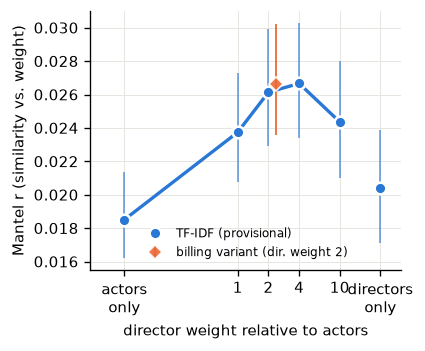

In [13]:
# x positions: 0 = actors only, 1..10 = director weight, right end = directors only; billing (= dir. weight 2) offset
xpos = {"actors": 0, "dir1": 1, "dir2": 2, "dir4": 4, "dir10": 10, "directors": 25}
order = list(xpos)
fig, ax = plt.subplots(figsize=(3.6, 3.0))
for k, col in zip(kinds, [C_OBS, C_ALT]):
    d = sq2.loc[k]
    xs = [xpos[s] for s in order]
    r = d.loc[order, "Mantel r (Pearson, weight)"]
    ax.errorbar(xs, r, yerr=[r - d.loc[order, "95% CI low"], d.loc[order, "95% CI high"] - r],
                fmt="none", ecolor=col, alpha=0.6, lw=1.2, capsize=0)
    ax.plot(xs[:-1], r.iloc[:-1], "-", color=col, lw=2)
    ax.plot(xs, r, "o", color=col, ms=7, markeredgecolor="white", markeredgewidth=1.5,
            label={"tfidf": "TF-IDF", "embed": "embeddings"}[k] + (" (provisional)" if k == "tfidf" and PROVISIONAL else ""))
    b = d.loc["billing"]
    ax.errorbar(2.35, b["Mantel r (Pearson, weight)"],
                yerr=[[b["Mantel r (Pearson, weight)"] - b["95% CI low"]], [b["95% CI high"] - b["Mantel r (Pearson, weight)"]]],
                fmt="D", color=C_GY, ms=6, markeredgecolor="white", ecolor=C_GY, alpha=0.9, lw=1.2,
                label="billing variant (dir. weight 2)" if k == kinds[0] else None)
ax.set_xscale("symlog", linthresh=1)
ax.set_xticks([0, 1, 2, 4, 10, 25], ["actors\nonly", "1", "2", "4", "10", "directors\nonly"])
ax.set_xlim(-0.3, 40)
ax.set(xlabel="director weight relative to actors", ylabel="Mantel r (similarity vs. weight)")
ax.legend(frameon=False, fontsize=7, loc="lower center")
fig.tight_layout(); fig.savefig(OUT / "fig2_sq2_correspondence.pdf"); plt.show()

## 6. Optional: disparity-filter backbone

Serrano et al. (2009) disparity filter on the `dir10` weights (α = 0.05). Most edges have weight 1, so the filter
only keeps edges that are much heavier than a film's other edges, mostly shared-director ties.
Are backbone edges more similar in plot than the removed edges? (Mann–Whitney, one-sided.)

In [14]:
rows = []
for s in ["dir2", "dir10"]:
    keep = nt.disparity_filter(W[s], alpha=0.05)[iu]
    lk = W[s][iu] > 0
    for k in kinds:
        a, b = SIM[k][iu][keep], SIM[k][iu][lk & ~keep]
        rows.append({"scheme": s, "similarity": k, "backbone edges": int(keep.sum()), "removed edges": len(b),
                     "mean sim backbone": a.mean(), "mean sim removed": b.mean(),
                     "p (MWU, backbone > removed)": stats.mannwhitneyu(a, b, alternative="greater").pvalue})
backbone = pd.DataFrame(rows)
backbone.to_csv(OUT / "backbone.csv", index=False)
backbone

,scheme,similarity,backbone edges,removed edges,mean sim backbone,mean sim removed,"p (MWU, backbone > removed)"
0,dir2,tfidf,36,11766,0.0942,0.0341,3.4711e-05
1,dir10,tfidf,983,10819,0.0407,0.0337,6.1736e-14


## 7. Notes for the paper

* Rewiring keeps degrees but not the community/genre structure, so both nulls are needed: the gap between the
  observed points and the grey band is "collaboration beyond degree"; the gap to the orange band is
  "collaboration beyond genre and era".
* The provisional TF-IDF keeps character names; a shared character name between unrelated films inflates
  similarity, so rerun with B's NER-cleaned matrices before reading the numbers.
* Rewired networks for C: `python network_tools.py rewire --n 100` → `network/null/rewired_<i>.tsv`.